# Evaluación Parcial N°3: Machine Learning
## Inteligencia Musical y Predicción de Popularidad de Canciones (Spotify Tracks)
*EP3: optimización de hiperparámetros, ensambles, validación cruzada y selección del modelo.*

| Campo | Detalle |
|---|---|
| Integrantes | Catalina Villegas y Javiera Fuenzalida |
| Sección | 002D |
| Asignatura | Machine Learning |
| Docente | Ignacio Meza |

## Metodología CRISP-DM

1. **Comprensión del negocio:** predecir qué canciones serán *hit* (popularidad >= 70) para priorizar marketing y listas editoriales.
2. **Comprensión de los datos:** exploración realizada en el notebook del EDA, que genera `Spotify_Tracks_Dataset_Clean.csv`.
3. **Preparación de los datos:** una fila por canción, variables numéricas, género y tonalidad en columnas 0/1, partición train/test.
4. **Modelado:** árbol de decisión simple, Random Forest (bagging), LightGBM (boosting) y K-Means (no supervisado).
5. **Evaluación:** validación cruzada de 5 pliegues, matriz de confusión, precision, recall, F1, ROC-AUC y PR-AUC.
6. **Despliegue:** notebook reproducible (`.ipynb`), informe técnico (`informe_tecnico.md`) y `README.md`.

**Herramientas:** Pandas y NumPy (datos), Matplotlib y Seaborn (gráficos), Scikit-learn (modelos, búsqueda de hiperparámetros y validación) y LightGBM (boosting).

## Problema de negocio y objetivos

Las plataformas de streaming reciben miles de canciones nuevas cada día. Anticipar cuáles pueden ser un éxito permite decidir dónde invertir en marketing y qué canciones incluir en listas editoriales.

**Objetivo general:** construir un modelo que prediga si una canción será *hit* a partir de sus atributos de audio y metadatos.

**Objetivos específicos:**
* Comparar un árbol de decisión simple contra dos ensambles: Random Forest (bagging) y LightGBM (boosting).
* Optimizar los hiperparámetros con Grid Search y Random Search.
* Evaluar la generalización con validación cruzada de 5 pliegues.
* Seleccionar el mejor modelo con criterios cuantitativos.
* Descubrir perfiles sonoros de canciones con K-Means.

## KPIs del negocio

| N° | KPI | Definición | Meta |
|---|---|---|---|
| 1 | Tasa global de hits | % de canciones con `popularity >= 70` | Referencia del azar |
| 2 | Hit ratio por género | % de hits dentro de cada género | Identificar los 5 géneros con mayor hit ratio |
| 3 | Índice de afinidad sonora | Correlación entre atributos de audio y popularidad | Medido en el EDA |
| 4 | Duración óptima | Intervalo de duración con mayor popularidad promedio | Medido en el EDA |
| 5 | Recall de Hit | Hits reales que el modelo detecta (test) | >= 0,60 |
| 6 | Lift de precisión | Precision de Hit / tasa de hits del test | >= 3 veces el azar |
| 7 | PR-AUC en validación cruzada | Calidad del ranking de hits | >= 3 veces el azar |
| 8 | Estabilidad | Desviación estándar de PR-AUC entre los 5 pliegues | <= 0,02 |
| 9 | Brecha train-validación | PR-AUC train menos PR-AUC validación | Menor que la del modelo con valores por defecto |
| 10 | Aporte de la optimización | PR-AUC optimizado menos PR-AUC por defecto | >= +0,01 en al menos un ensamble |
| 11 | Aporte del ensamble | PR-AUC del mejor ensamble menos el del árbol simple | >= +0,05 |
| 12 | Latencia | Milisegundos para predecir 1.000 canciones | <= 1.000 |
| 13 | Equidad | Diferencia de recall entre artistas vistos y nuevos | <= 0,20 |

## Preparación de los datos

In [19]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, silhouette_score)

### Carga de datos

El notebook funciona en el repositorio local (`notebooks/`, datos en `../data`) y en Google Colab (CSV subido a la sesión).

In [20]:
ARCHIVO = 'Spotify_Tracks_Dataset_Clean.csv'

if Path('../data', ARCHIVO).exists():
    RUTA_DATOS, RUTA_IMAGENES = Path('../data', ARCHIVO), Path('../images')
elif Path('data', ARCHIVO).exists():
    RUTA_DATOS, RUTA_IMAGENES = Path('data', ARCHIVO), Path('images')
else:
    RUTA_DATOS, RUTA_IMAGENES = Path(ARCHIVO), Path('images')

RUTA_IMAGENES.mkdir(exist_ok=True)
df = pd.read_csv(RUTA_DATOS)
print(f'Dataset cargado: {df.shape[0]} filas x {df.shape[1]} columnas')
df.head()

Dataset cargado: 42409 filas x 32 columnas


,track_id,artists,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,...,acoustic_energy,danceability_diff_genre,energy_diff_genre,loudness_diff_genre,valence_diff_genre,is_hit,duration_min,speechiness_log,liveness_log,instrumentalness_log
0,4pR4oQJULf7FDB54TleMyH,Limoblaze;Lecrae;Happi,64,168000.0,0,0.443,0.778,0,-7.564,0,...,0.590502,-0.226192,0.075855,0.196109,-0.068724,0,2.800000,0.235862,0.194744,0.000000
1,4Ds4bq6aqOSAp1T7DikOi4,Criolo,44,318360.0,0,0.580,0.800,6,-7.528,1,...,0.575200,-0.089192,0.097855,0.232109,-0.213724,0,5.306000,0.296394,0.068406,0.000000
2,7nYbKsvhM88mHCmFsAIQVp,Criolo,42,171989.0,0,0.805,0.746,1,-5.211,0,...,0.568452,0.135808,0.043855,2.549109,0.020276,0,2.866483,0.169743,0.194744,0.000000
3,7gVNP7rI9UBZndge0ulKfL,Criolo,46,205440.0,0,0.582,0.660,7,-4.988,0,...,0.396660,-0.087192,-0.042145,2.772109,-0.212724,0,3.424000,0.052972,0.119559,0.000000
4,1hLvWelTny8vttEEZIXVjw,Criolo,44,220800.0,0,0.776,0.314,2,-9.513,1,...,0.037366,0.106808,-0.388145,-1.752891,-0.220724,0,3.680000,0.033435,0.130151,0.000723


### Variable objetivo y limpieza final

* `is_hit` vale 1 si `popularity >= 70` y 0 en caso contrario.
* Una misma canción puede aparecer en varios géneros. Se deja **una fila por canción** para que la misma canción no quede a la vez en train y en test.
* Se eliminan las columnas que no sirven para predecir o que revelan la respuesta (`popularity`, identificadores y texto).
* El género y la tonalidad (`key`) se convierten en columnas 0/1 con `pd.get_dummies`.
* Los árboles no necesitan escalar las variables, por eso no se usa `StandardScaler` en la clasificación.

In [21]:
UMBRAL_HIT = 70

# Una fila por canción
df = df.drop_duplicates(subset='track_id')

# Variable objetivo
df['is_hit'] = (df['popularity'] >= UMBRAL_HIT).astype(int)
df['explicit'] = df['explicit'].astype(int)

# Cifras reales del dataset
n_filas = len(df)
n_generos = df['track_genre'].nunique()
tasa_hit = df['is_hit'].mean()
print(f'{n_filas} canciones | {n_generos} géneros | tasa de hits: {tasa_hit:.2%}')
print(f'Si siempre se predijera "No Hit", la exactitud sería {1 - tasa_hit:.1%}')

# Variables predictoras (X) y objetivo (y)
columnas_a_quitar = ['track_id', 'artists', 'popularity', 'is_hit', 'album_name', 'track_name',
                     'duration_min', 'speechiness_log', 'liveness_log', 'instrumentalness_log']
X = df.drop(columns=columnas_a_quitar, errors='ignore')
y = df['is_hit']

# Género y tonalidad en columnas 0/1
X = pd.get_dummies(X, columns=['track_genre', 'key'])
X.columns = X.columns.str.replace('[^0-9a-zA-Z_]', '_', regex=True)

# 80 % entrenamiento y 20 % prueba, con la misma proporción de hits en ambos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Peso de la clase minoritaria: cuántos No Hit hay por cada Hit en train
ratio = (y_train == 0).sum() / (y_train == 1).sum()

print(f'Train: {len(X_train)} filas | Test: {len(X_test)} filas | Variables: {X_train.shape[1]}')
print(f'Tasa de hits en train: {y_train.mean():.2%} | en test: {y_test.mean():.2%}')
print(f'Desbalance en train: {ratio:.1f} No Hit por cada Hit')

37497 canciones | 49 géneros | tasa de hits: 5.68%
Si siempre se predijera "No Hit", la exactitud sería 94.3%
Train: 29997 filas | Test: 7500 filas | Variables: 83
Tasa de hits en train: 5.67% | en test: 5.68%
Desbalance en train: 16.6 No Hit por cada Hit


In [22]:
# KPI 2: géneros con mayor hit ratio
hit_ratio_genero = (df.groupby('track_genre')['is_hit'].mean() * 100).sort_values(ascending=False)
print('Top 5 géneros por hit ratio (%):')
print(hit_ratio_genero.head(5).round(2))

Top 5 géneros por hit ratio (%):
track_genre
electro    39.59
pop        39.36
house      32.64
indie      32.35
edm        28.69
Name: is_hit, dtype: float64


## Optimización de hiperparámetros

Un **hiperparámetro** lo define el ingeniero antes de entrenar (por ejemplo, la profundidad de un árbol). Un **parámetro** lo aprende el modelo de los datos.

| Modelo | Estrategia | Motivo |
|---|---|---|
| Árbol simple | **Grid Search** | Pocos hiperparámetros y pocos valores: se prueban todas las combinaciones |
| Random Forest | **Random Search** | Más hiperparámetros: se limita el costo con `n_iter` |
| LightGBM | **Random Search** | Espacio grande: la rejilla completa crecería de forma exponencial |

Todas las búsquedas usan validación cruzada de 3 pliegues y optimizan **PR-AUC** (`average_precision`), porque los hits son pocos y la exactitud no sirve. El desbalance se compensa con **pesos de clase**, sin crear datos sintéticos.

In [23]:
# Pliegues para las búsquedas (3, para que sea rápido) y para la validación final (5)
cv_busqueda = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1) Árbol simple: Grid Search (6 combinaciones x 3 pliegues)
inicio = time.perf_counter()
rejilla_arbol = {'max_depth': [3, 5, 8], 'min_samples_leaf': [20, 50]}
busq_arbol = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                          rejilla_arbol, scoring='average_precision', cv=cv_busqueda)
busq_arbol.fit(X_train, y_train)
t_arbol = time.perf_counter() - inicio
print(f'Árbol simple | mejor PR-AUC: {busq_arbol.best_score_:.3f} | {t_arbol:.0f} s')
print('Mejores hiperparámetros:', busq_arbol.best_params_)

Árbol simple | mejor PR-AUC: 0.143 | 16 s
Mejores hiperparámetros: {'max_depth': 8, 'min_samples_leaf': 20}


In [24]:
# 2) Random Forest: Random Search (6 combinaciones x 3 pliegues)
inicio = time.perf_counter()
espacio_rf = {'n_estimators': [100, 150],
              'max_depth': [8, 12, 16],
              'min_samples_leaf': [5, 10, 20],
              'max_features': ['sqrt', 0.3]}
busq_rf = RandomizedSearchCV(RandomForestClassifier(class_weight='balanced_subsample', random_state=42, n_jobs=-1),
                             espacio_rf, n_iter=6, scoring='average_precision',
                             cv=cv_busqueda, random_state=42)
busq_rf.fit(X_train, y_train)
t_rf = time.perf_counter() - inicio
print(f'Random Forest | mejor PR-AUC: {busq_rf.best_score_:.3f} | {t_rf:.0f} s')
print('Mejores hiperparámetros:', busq_rf.best_params_)

Random Forest | mejor PR-AUC: 0.305 | 222 s
Mejores hiperparámetros: {'n_estimators': 150, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 16}


In [25]:
# 3) LightGBM: Random Search (8 combinaciones x 3 pliegues)
inicio = time.perf_counter()
espacio_lgbm = {'n_estimators': [100, 200, 300],
                'learning_rate': [0.03, 0.05, 0.1],
                'num_leaves': [15, 31, 63],
                'max_depth': [4, 6, 8],
                'min_child_samples': [20, 50, 100]}
busq_lgbm = RandomizedSearchCV(LGBMClassifier(scale_pos_weight=ratio, random_state=42, n_jobs=-1, verbose=-1),
                               espacio_lgbm, n_iter=8, scoring='average_precision',
                               cv=cv_busqueda, random_state=42)
busq_lgbm.fit(X_train, y_train)
t_lgbm = time.perf_counter() - inicio
print(f'LightGBM | mejor PR-AUC: {busq_lgbm.best_score_:.3f} | {t_lgbm:.0f} s')
print('Mejores hiperparámetros:', busq_lgbm.best_params_)
print(f'\nCosto de la optimización: árbol {t_arbol:.0f} s, Random Forest {t_rf:.0f} s, LightGBM {t_lgbm:.0f} s')

LightGBM | mejor PR-AUC: 0.349 | 34 s
Mejores hiperparámetros: {'num_leaves': 15, 'n_estimators': 300, 'min_child_samples': 50, 'max_depth': 8, 'learning_rate': 0.05}

Costo de la optimización: árbol 16 s, Random Forest 222 s, LightGBM 34 s


## Ensambles y validación cruzada

Se comparan los modelos con **la misma validación cruzada de 5 pliegues**, usando solo los datos de entrenamiento:

* **Árbol simple:** modelo de referencia, sin ensamble.
* **Random Forest (Bagging):** muchos árboles entrenados en paralelo con muestras aleatorias; reduce la **varianza** y el sobreajuste.
* **LightGBM (Boosting):** árboles en secuencia, cada uno corrige los errores del anterior; reduce el **sesgo**.
* Cada modelo se evalúa con sus **valores por defecto** y **optimizado**, para medir cuánto aporta la optimización.

En cada pliegue se calcula la métrica en validación y en entrenamiento:
* **Desviación estándar** entre pliegues: si es baja, el modelo es estable.
* **Brecha** (train menos validación): si es grande, hay sobreajuste.

In [26]:
modelos = {
    'Árbol (defecto)': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Árbol (optimizado)': busq_arbol.best_estimator_,
    'RandomForest (defecto)': RandomForestClassifier(class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    'RandomForest (optimizado)': busq_rf.best_estimator_,
    'LightGBM (defecto)': LGBMClassifier(scale_pos_weight=ratio, random_state=42, n_jobs=-1, verbose=-1),
    'LightGBM (optimizado)': busq_lgbm.best_estimator_,
}

metricas = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc',
            'recall': 'recall', 'precision': 'precision', 'f1': 'f1'}

resultados_cv = {}
for nombre, modelo in modelos.items():
    resultados_cv[nombre] = cross_validate(modelo, X_train, y_train, cv=cv_final,
                                           scoring=metricas, return_train_score=True)
    print(f'{nombre}: listo')

Árbol (defecto): listo
Árbol (optimizado): listo
RandomForest (defecto): listo
RandomForest (optimizado): listo
LightGBM (defecto): listo
LightGBM (optimizado): listo


In [27]:
filas = []
for nombre, r in resultados_cv.items():
    filas.append({'modelo': nombre,
                  'PR-AUC val (media)': r['test_pr_auc'].mean(),
                  'PR-AUC val (desv.)': r['test_pr_auc'].std(),
                  'PR-AUC train': r['train_pr_auc'].mean(),
                  'ROC-AUC val': r['test_roc_auc'].mean(),
                  'Recall val': r['test_recall'].mean(),
                  'Precision val': r['test_precision'].mean(),
                  'F1 val': r['test_f1'].mean(),
                  'Tiempo de ajuste (s)': r['fit_time'].mean()})

tabla_cv = pd.DataFrame(filas).set_index('modelo')
tabla_cv['Brecha train-val'] = tabla_cv['PR-AUC train'] - tabla_cv['PR-AUC val (media)']
tabla_cv.round(3)

,PR-AUC val (media),PR-AUC val (desv.),PR-AUC train,ROC-AUC val,Recall val,Precision val,F1 val,Tiempo de ajuste (s),Brecha train-val
modelo,,,,,,,,,
Árbol (defecto),0.108,0.003,0.998,0.606,0.259,0.249,0.254,1.727,0.890
Árbol (optimizado),0.140,0.013,0.164,0.771,0.854,0.124,0.216,0.682,0.024
RandomForest (defecto),0.298,0.024,0.978,0.883,0.076,0.352,0.125,10.324,0.681
RandomForest (optimizado),0.318,0.018,0.483,0.873,0.764,0.191,0.306,20.614,0.165
LightGBM (defecto),0.348,0.021,0.752,0.908,0.773,0.254,0.382,1.061,0.405
LightGBM (optimizado),0.367,0.024,0.557,0.912,0.855,0.224,0.355,1.513,0.190


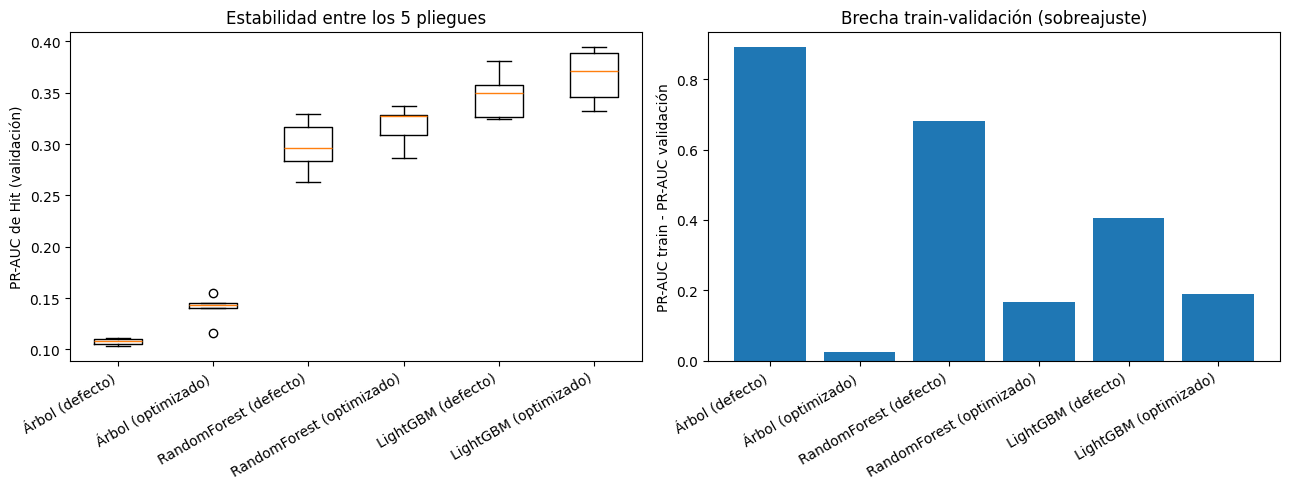

In [28]:
nombres = list(resultados_cv.keys())
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

ejes[0].boxplot([resultados_cv[n]['test_pr_auc'] for n in nombres])
ejes[0].set_xticklabels(nombres, rotation=30, ha='right')
ejes[0].set_ylabel('PR-AUC de Hit (validación)')
ejes[0].set_title('Estabilidad entre los 5 pliegues')

ejes[1].bar(range(len(nombres)), tabla_cv['Brecha train-val'])
ejes[1].set_xticks(range(len(nombres)))
ejes[1].set_xticklabels(nombres, rotation=30, ha='right')
ejes[1].set_ylabel('PR-AUC train - PR-AUC validación')
ejes[1].set_title('Brecha train-validación (sobreajuste)')

plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'cv_estabilidad_brecha.png', bbox_inches='tight')
plt.show()

## Selección del modelo

**Regla de decisión (definida antes de mirar el test):**

1. Entre los modelos optimizados, se elige el de **mayor PR-AUC medio en validación cruzada**.
2. Se verifican su **estabilidad** (desviación estándar), su **brecha** train-validación, su **latencia** y su **equidad** por subgrupos.
3. El conjunto de **test se usa una sola vez**, para informar el desempeño final.

In [29]:
finalistas = ['Árbol (optimizado)', 'RandomForest (optimizado)', 'LightGBM (optimizado)']
elegido = tabla_cv.loc[finalistas, 'PR-AUC val (media)'].idxmax()
print(f'Modelo seleccionado: {elegido}')

# Desempeño en test de los tres finalistas (se usa una sola vez)
filas_test = {}
for nombre in finalistas:
    modelo = modelos[nombre]
    inicio = time.perf_counter()
    proba = modelo.predict_proba(X_test)[:, 1]
    latencia = (time.perf_counter() - inicio) / len(X_test) * 1_000_000   # ms por 1.000 canciones
    pred = (proba >= 0.5).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    precision = precision_score(y_test, pred, zero_division=0)
    filas_test[nombre] = {'Precision Hit': precision,
                          'Recall Hit': recall_score(y_test, pred, zero_division=0),
                          'F1 Hit': f1_score(y_test, pred, zero_division=0),
                          'ROC-AUC': roc_auc_score(y_test, proba),
                          'PR-AUC': average_precision_score(y_test, proba),
                          'Hits detectados': vp, 'Hits perdidos': fn, 'Falsas alarmas': fp,
                          'Lift vs azar': precision / y_test.mean(),
                          'Latencia (ms por 1.000 canciones)': latencia}

tabla_test = pd.DataFrame(filas_test).T
tabla_test.round(3)

Modelo seleccionado: LightGBM (optimizado)


,Precision Hit,Recall Hit,F1 Hit,ROC-AUC,PR-AUC,Hits detectados,Hits perdidos,Falsas alarmas,Lift vs azar,Latencia (ms por 1.000 canciones)
Árbol (optimizado),0.143,0.822,0.244,0.803,0.167,350.0,76.0,2095.0,2.520,0.951
RandomForest (optimizado),0.189,0.770,0.303,0.885,0.354,328.0,98.0,1411.0,3.321,14.860
LightGBM (optimizado),0.225,0.883,0.359,0.921,0.392,376.0,50.0,1295.0,3.962,10.944


              precision    recall  f1-score   support

      No Hit       0.99      0.82      0.90      7074
         Hit       0.23      0.88      0.36       426

    accuracy                           0.82      7500
   macro avg       0.61      0.85      0.63      7500
weighted avg       0.95      0.82      0.87      7500



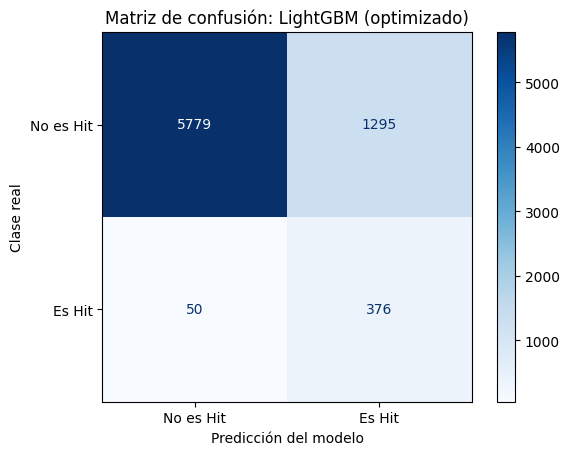

In [30]:
# Matriz de confusión del modelo seleccionado
pred_elegido = (modelos[elegido].predict_proba(X_test)[:, 1] >= 0.5).astype(int)
print(classification_report(y_test, pred_elegido, target_names=['No Hit', 'Hit'], zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred_elegido, display_labels=['No es Hit', 'Es Hit'],
                                        cmap='Blues', values_format='d')
plt.title(f'Matriz de confusión: {elegido}')
plt.xlabel('Predicción del modelo')
plt.ylabel('Clase real')
plt.savefig(RUTA_IMAGENES / 'matriz_confusion_elegido.png', bbox_inches='tight')
plt.show()

### Equidad por subgrupos

Se revisa si el modelo seleccionado funciona parecido en distintos grupos de canciones: artistas vistos o nuevos (no presentes en train) y canciones con o sin contenido explícito.

In [31]:
pred_sub = pd.Series(pred_elegido, index=X_test.index)
artista_visto = df.loc[X_test.index, 'artists'].isin(df.loc[X_train.index, 'artists'])
es_explicito = df.loc[X_test.index, 'explicit'] == 1

subgrupos = {'Artista visto en train': artista_visto,
             'Artista nuevo': ~artista_visto,
             'Contenido explícito': es_explicito,
             'Sin contenido explícito': ~es_explicito}

filas_eq = []
for nombre, mascara in subgrupos.items():
    real = y_test[mascara]
    pred_grupo = pred_sub[mascara]
    hits = int(real.sum())
    alertas = int(pred_grupo.sum())
    filas_eq.append({'subgrupo': nombre, 'canciones': int(mascara.sum()), 'hits reales': hits,
                     'tasa de alertas': pred_grupo.mean(),
                     'recall Hit': recall_score(real, pred_grupo, zero_division=0) if hits > 0 else np.nan,
                     'precision Hit': precision_score(real, pred_grupo, zero_division=0) if alertas > 0 else np.nan})

tabla_equidad = pd.DataFrame(filas_eq).set_index('subgrupo')
tabla_equidad.round(3)

,canciones,hits reales,tasa de alertas,recall Hit,precision Hit
subgrupo,,,,,
Artista visto en train,5562,284,0.220,0.884,0.205
Artista nuevo,1938,142,0.230,0.880,0.280
Contenido explícito,719,71,0.323,0.873,0.267
Sin contenido explícito,6781,355,0.212,0.885,0.218


### Importancia de las variables

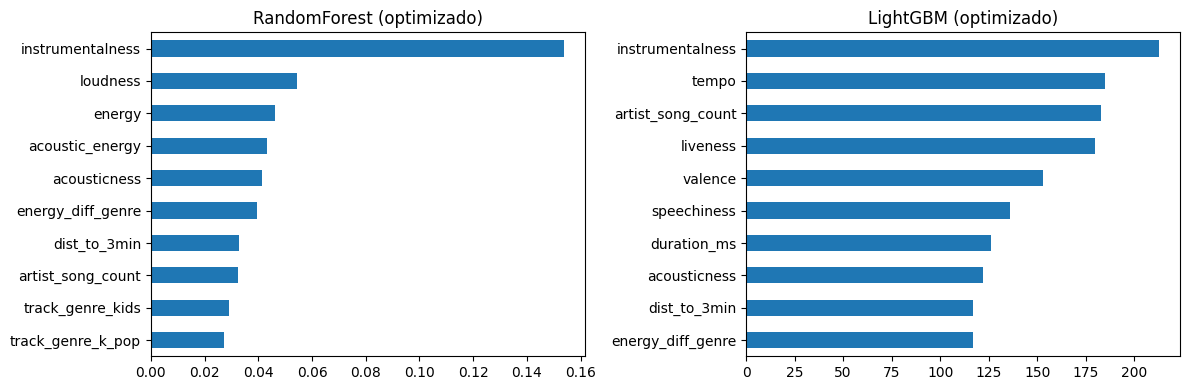

In [32]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, nombre in zip(ejes, ['RandomForest (optimizado)', 'LightGBM (optimizado)']):
    importancia = pd.Series(modelos[nombre].feature_importances_, index=X_train.columns)
    importancia.sort_values().tail(10).plot.barh(ax=eje, title=nombre)
plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'importancia_ensambles.png', bbox_inches='tight')
plt.show()

### Cumplimiento de los KPIs

In [33]:
azar = y_test.mean()
r = tabla_test.loc[elegido]
cv_e = tabla_cv.loc[elegido]
version_defecto = elegido.replace('optimizado', 'defecto')

aporte_opt = max(tabla_cv.loc['RandomForest (optimizado)', 'PR-AUC val (media)'] - tabla_cv.loc['RandomForest (defecto)', 'PR-AUC val (media)'],
                 tabla_cv.loc['LightGBM (optimizado)', 'PR-AUC val (media)'] - tabla_cv.loc['LightGBM (defecto)', 'PR-AUC val (media)'])
aporte_ens = (tabla_cv.loc[['RandomForest (optimizado)', 'LightGBM (optimizado)'], 'PR-AUC val (media)'].max()
              - tabla_cv.loc['Árbol (optimizado)', 'PR-AUC val (media)'])
dif_equidad = abs(tabla_equidad.loc['Artista visto en train', 'recall Hit'] - tabla_equidad.loc['Artista nuevo', 'recall Hit'])

filas_kpi = [
    ('5. Recall de Hit (test)', r['Recall Hit'], '>= 0,60', r['Recall Hit'] >= 0.60),
    ('6. Lift de precisión (test)', r['Lift vs azar'], '>= 3', r['Lift vs azar'] >= 3),
    ('7. PR-AUC en validación cruzada', cv_e['PR-AUC val (media)'], f'>= {3 * azar:.3f} (3 veces el azar)', cv_e['PR-AUC val (media)'] >= 3 * azar),
    ('8. Desviación estándar de PR-AUC', cv_e['PR-AUC val (desv.)'], '<= 0,02', cv_e['PR-AUC val (desv.)'] <= 0.02),
    ('9. Brecha train-val (optimizado)', cv_e['Brecha train-val'], f'< {tabla_cv.loc[version_defecto, "Brecha train-val"]:.3f} (defecto)', cv_e['Brecha train-val'] < tabla_cv.loc[version_defecto, 'Brecha train-val']),
    ('10. Aporte de la optimización', aporte_opt, '>= 0,01', aporte_opt >= 0.01),
    ('11. Aporte del ensamble', aporte_ens, '>= 0,05', aporte_ens >= 0.05),
    ('12. Latencia (ms por 1.000 canciones)', r['Latencia (ms por 1.000 canciones)'], '<= 1000', r['Latencia (ms por 1.000 canciones)'] <= 1000),
    ('13. Diferencia de recall visto vs nuevo', dif_equidad, '<= 0,20', bool(dif_equidad <= 0.20)),
]
tabla_kpi = pd.DataFrame(filas_kpi, columns=['KPI', 'Valor', 'Meta', '¿Cumple?'])
tabla_kpi['Valor'] = tabla_kpi['Valor'].round(3)
tabla_kpi

,KPI,Valor,Meta,¿Cumple?
0,5. Recall de Hit (test),0.883,">= 0,60",True
1,6. Lift de precisión (test),3.962,>= 3,True
2,7. PR-AUC en validación cruzada,0.367,>= 0.170 (3 veces el azar),True
3,8. Desviación estándar de PR-AUC,0.024,"<= 0,02",False
4,9. Brecha train-val (optimizado),0.190,< 0.405 (defecto),True
5,10. Aporte de la optimización,0.020,">= 0,01",True
6,11. Aporte del ensamble,0.227,">= 0,05",True
7,12. Latencia (ms por 1.000 canciones),10.944,<= 1000,True
8,13. Diferencia de recall visto vs nuevo,0.004,"<= 0,20",True


## Modelado no supervisado: K-Means

El objetivo es descubrir **perfiles sonoros** de canciones. Se usan solo los atributos de audio, sin `popularity`, `is_hit`, artista ni género, para que los grupos reflejen el sonido y no la variable objetivo.

* Las variables se **escalan** (`StandardScaler`), porque K-Means usa distancias.
* El número de grupos `k` se revisa con el **método del codo** (inercia) y el **coeficiente de silueta**. Se elige el `k` entre 3 y 8 con mayor silueta.

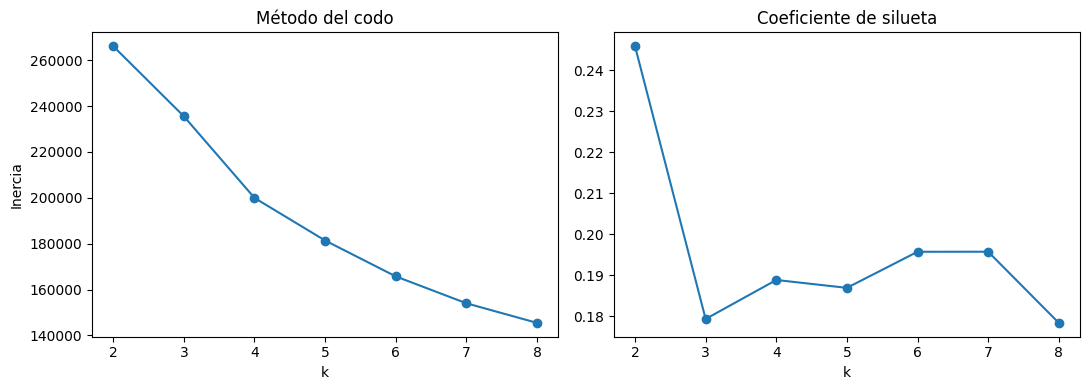

{2: 0.246, 3: 0.179, 4: 0.189, 5: 0.187, 6: 0.196, 7: 0.196, 8: 0.178}
k elegido: 7


In [34]:
AUDIO = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo']

Z = StandardScaler().fit_transform(df[AUDIO])
muestra = np.random.RandomState(42).choice(len(Z), min(5000, len(Z)), replace=False)

ks = list(range(2, 9))
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z[muestra], km.labels_[muestra]))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(ks, inercias, marker='o')
ejes[0].set_title('Método del codo')
ejes[0].set_xlabel('k')
ejes[0].set_ylabel('Inercia')
ejes[1].plot(ks, siluetas, marker='o')
ejes[1].set_title('Coeficiente de silueta')
ejes[1].set_xlabel('k')
plt.tight_layout()
plt.savefig(RUTA_IMAGENES / 'kmeans_k.png', bbox_inches='tight')
plt.show()

# k con mayor silueta entre 3 y 8
K = ks[1:][int(np.argmax(siluetas[1:]))]
print({k: round(float(s), 3) for k, s in zip(ks, siluetas)})
print(f'k elegido: {K}')

In [35]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)
df_grupos = df.copy()
df_grupos['grupo'] = kmeans.labels_

# Perfil de cada grupo: tamaño, tasa de hits, popularidad y promedio de cada atributo de audio
perfil = df_grupos.groupby('grupo').agg(
    canciones=('is_hit', 'size'),
    tasa_hit=('is_hit', 'mean'),
    popularidad_media=('popularity', 'mean'),
    **{c: (c, 'mean') for c in AUDIO})
perfil['generos_top'] = df_grupos.groupby('grupo')['track_genre'].agg(
    lambda s: ', '.join(s.value_counts().head(3).index))
display(perfil.round(2))

# Atributos que más se alejan del promedio en cada grupo (centroides en unidades estándar)
centros = pd.DataFrame(kmeans.cluster_centers_, columns=AUDIO)
for g in range(K):
    altos = ', '.join(centros.loc[g].nlargest(2).index)
    bajos = ', '.join(centros.loc[g].nsmallest(2).index)
    print(f'Grupo {g}: más altos en {altos} | más bajos en {bajos}')

,canciones,tasa_hit,popularidad_media,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,generos_top
grupo,,,,,,,,,,,,,
0,5210,0.01,22.83,0.59,0.73,-8.81,0.07,0.12,0.81,0.16,0.39,126.72,"detroit-techno, study, chicago-house"
1,7556,0.06,37.68,0.55,0.38,-10.71,0.06,0.71,0.05,0.17,0.43,113.43,"tango, honky-tonk, chill"
2,7733,0.06,37.21,0.45,0.84,-5.16,0.09,0.06,0.08,0.20,0.34,142.84,"heavy-metal, grunge, black-metal"
3,856,0.00,23.31,0.56,0.71,-11.16,0.89,0.79,0.00,0.74,0.43,97.33,"comedy, kids, sad"
4,3054,0.01,29.82,0.40,0.18,-20.08,0.05,0.87,0.76,0.15,0.23,106.52,"piano, disney, classical"
5,2048,0.04,31.60,0.52,0.79,-6.48,0.10,0.19,0.15,0.71,0.46,125.23,"heavy-metal, happy, grindcore"
6,11040,0.09,38.89,0.70,0.73,-6.28,0.10,0.17,0.03,0.16,0.65,117.56,"kids, j-dance, k-pop"


Grupo 0: más altos en instrumentalness, energy | más bajos en acousticness, liveness
Grupo 1: más altos en acousticness, danceability | más bajos en energy, instrumentalness
Grupo 2: más altos en energy, tempo | más bajos en acousticness, danceability
Grupo 3: más altos en speechiness, liveness | más bajos en tempo, instrumentalness
Grupo 4: más altos en instrumentalness, acousticness | más bajos en loudness, energy
Grupo 5: más altos en liveness, energy | más bajos en acousticness, danceability
Grupo 6: más altos en valence, danceability | más bajos en instrumentalness, acousticness


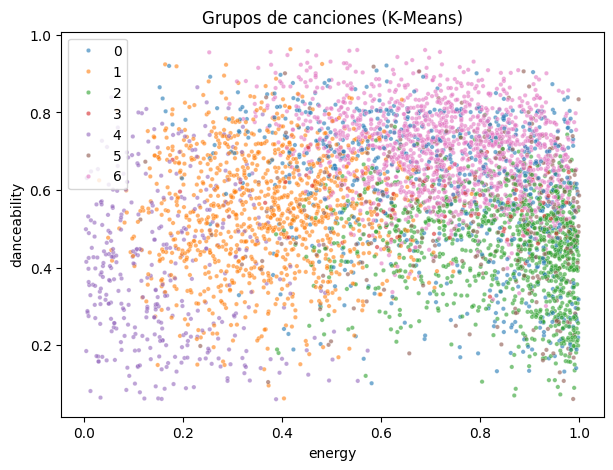

In [36]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=df_grupos['energy'].values[muestra], y=df_grupos['danceability'].values[muestra],
                hue=df_grupos['grupo'].values[muestra], palette='tab10', s=10, alpha=0.6)
plt.xlabel('energy')
plt.ylabel('danceability')
plt.title('Grupos de canciones (K-Means)')
plt.savefig(RUTA_IMAGENES / 'clusters_kmeans.png', bbox_inches='tight')
plt.show()

## Sesgos, limitaciones y ética

* **Selección de géneros:** el dataset incluye los 25 géneros más populares y los 25 menos populares, elegidos según la popularidad promedio. Esa selección usa la variable que luego se predice y no refleja el catálogo real.
* **Sesgo de retroalimentación:** la popularidad refleja lo que Spotify ya promovió, así que el modelo tiende a repetir esas decisiones.
* **Artistas nuevos:** el artista no es una variable del modelo; solo se usa la cantidad de canciones del artista en el dataset. Se revisa el desempeño en artistas vistos y nuevos.
* **Una fila por canción:** al conservar un solo género por canción se pierde parte de la información de géneros múltiples.
* **Privacidad:** el dataset contiene metadatos públicos de canciones, sin datos personales de oyentes.
* **Uso responsable:** el modelo es un filtro de apoyo para priorizar revisión humana, no una decisión automática que descarte obras por su perfil sonoro.

## Registro de decisiones

| N° | Decisión | Motivo |
|---|---|---|
| 1 | Hit si `popularity >= 70` | Umbral definido en el EDA |
| 2 | Una fila por canción (`drop_duplicates` por `track_id`) | Evita la misma canción en train y en test |
| 3 | Se eliminan `popularity`, `track_id`, `artists` y texto | Revelan la respuesta o no sirven como variable predictora |
| 4 | Género y tonalidad con `pd.get_dummies` | Codificación simple, sin usar la variable objetivo |
| 5 | Sin escalado en clasificación | Los modelos de árboles no lo necesitan |
| 6 | Pesos de clase en lugar de sobremuestreo | Compensa el desbalance sin crear datos sintéticos |
| 7 | Métrica principal: PR-AUC de Hit, recall y matriz de confusión | Con pocos hits, la exactitud no es informativa |
| 8 | Grid Search para el árbol y Random Search para los ensambles | Grid con pocos hiperparámetros; Random con espacios más grandes |
| 9 | Validación cruzada de 5 pliegues estratificada, solo en train | Estimación más robusta; el test queda intacto |
| 10 | Selección por mayor PR-AUC medio en validación cruzada | Criterio fijado antes de usar el test |
| 11 | K-Means con atributos de audio escalados; k con mayor silueta entre 3 y 8 | Perfiles sonoros sin sesgo de la variable objetivo |

## Conclusiones

Los resultados numéricos se resumen en la tabla de validación cruzada, la tabla de test y la tabla de KPIs de este notebook. La interpretación, las limitaciones y las recomendaciones para el negocio se desarrollan en `informe_tecnico.md`.

## Resumen de resultados en texto

Imprime todas las tablas en formato de texto, listas para copiar al informe técnico.

In [37]:
print('=== Validación cruzada de 5 pliegues ===')
print(tabla_cv.round(3).to_string())
print('\n=== Desempeño en test ===')
print(tabla_test.round(3).to_string())
print('\n=== Equidad por subgrupos ===')
print(tabla_equidad.round(3).to_string())
print('\n=== KPIs ===')
print(tabla_kpi.to_string())
print('\n=== Perfiles K-Means ===')
print(perfil.round(2).to_string())
print(f'\nk elegido: {K} | siluetas: { {k: round(float(s), 3) for k, s in zip(ks, siluetas)} }')
print(f'\nTiempos de búsqueda (s): árbol {t_arbol:.0f}, Random Forest {t_rf:.0f}, LightGBM {t_lgbm:.0f}')

=== Validación cruzada de 5 pliegues ===
                           PR-AUC val (media)  PR-AUC val (desv.)  PR-AUC train  ROC-AUC val  Recall val  Precision val  F1 val  Tiempo de ajuste (s)  Brecha train-val
modelo                                                                                                                                                                 
Árbol (defecto)                         0.108               0.003         0.998        0.606       0.259          0.249   0.254                 1.727             0.890
Árbol (optimizado)                      0.140               0.013         0.164        0.771       0.854          0.124   0.216                 0.682             0.024
RandomForest (defecto)                  0.298               0.024         0.978        0.883       0.076          0.352   0.125                10.324             0.681
RandomForest (optimizado)               0.318               0.018         0.483        0.873       0.764          0.191